<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">Cenário 1 — Vitória Clara</h1>
</div>

# Contextualização do Experimento
Neste cenário, analisamos um teste A/B cujo objetivo é avaliar se a alteração de um botão na página inicial produz um aumento na taxa de cliques (CTR).

Para isso, comparamos duas versões:

- **Grupo de controle (A):** utiliza o botão original, com o texto "Garantir um teste gratuito".
- **Grupo experimental (B):** utiliza o botão modificado, com o texto "Inscreva-se agora".

## Hipóteses estatísticas
Para avaliar o efeito da alteração, estabelecemos as seguintes hipóteses:
- **Hipótese Nula (H₀):** não existe diferença entre as taxas de cliques dos grupos de controle e experimental.
- **Hipótese Alternativa (H₁):** existe diferença entre as taxas de cliques dos grupos de controle e experimental.

Os parâmetros estatísticos utilizados neste experimento seguem o planejamento experimental documentado no README do projeto.

## Descrição do Dataset
O conjunto de dados contém os registros de exposição dos usuários às duas variantes do experimento e a indicação de ocorrência ou não de um clique.

Cada linha representa um registro de usuário no experimento, contendo as seguintes variáveis:

| Variável | Descrição |
|---|---|
| `user_id` | Identificador único do usuário. |
| `click` | Indica se ocorreu um clique: 1 para sim e 0 para não. |
| `group` | Identifica a variante à qual o usuário foi atribuído: `con` (controle) ou `exp` (experimental). |
| `timestamp` | Data e horário do registro de exposição do usuário. |

**Observação:** a variável `click` será utilizada para calcular a taxa de cliques de cada grupo, enquanto `group` permitirá separar os resultados entre as variantes experimentais.

## Análise Exploratória e Validação dos Dados
Antes de realizar o teste estatístico, vamos examinar o conjunto de dados para compreender sua estrutura e verificar sua consistência. Nesta etapa, serão avaliados:
- Dimensões do dataset e tipos das variáveis.
- Existência de valores ausentes e registros duplicados.
- Distribuição dos usuários entre os grupos.
- Quantidade de cliques e não cliques em cada variante.
- Taxas de cliques observadas em cada grupo.

Após essa validação, os dados estarão preparados para a aplicação dos testes estatísticos e interpretação dos resultados.

<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">1 Importando Bibliotecas e Dataset</h1>
</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import norm, chisquare

import sys
import os

sys.path.append(os.path.abspath(".."))
import utils.analysis_utils as func

#Configuração do matplotlib
plt.style.use('default')

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("../data-raw/user-data-cenario1-vitoria_clara.csv", parse_dates=["timestamp"])
display(df)

,user_id,click,group,timestamp
0,1,0,exp,2024-01-01 00:00:33
1,2,0,exp,2024-01-01 00:02:33
2,3,0,exp,2024-01-01 00:06:20
3,4,0,exp,2024-01-01 00:07:19
4,5,1,exp,2024-01-01 00:11:36
...,...,...,...,...
19995,19996,0,exp,2024-01-14 23:48:59
19996,19997,1,con,2024-01-14 23:49:55
19997,19998,1,con,2024-01-14 23:50:26
19998,19999,0,con,2024-01-14 23:58:10


## 1.1 Checagens Básicas de Qualidade

Antes de qualquer teste: tipos, nulos, duplicados e valores esperados.

In [3]:
func.df_summary_report(df)

,Coluna,Tipo,Quantidade de Dados Não Vazios,Quantidade de Dados Vazios,Valores Únicos,Valor mais Frequente,Frequência,Porcentagem de Unicidade,Porcentagem de Valor Vazios (%),Consumo de Memória - Total: 1.45 (MB)
0,user_id,int64,20000,0,20000,1,1,100.00,0.00,0.152588
1,click,int64,20000,0,2,0.000000,15775,0.01,0.00,0.152588
2,group,str,20000,0,2,con,10000,0.01,0.00,0.991821
3,timestamp,datetime64[us],20000,0,19845,2024-01-01 02:04:07,2,99.22,0.00,0.152588


In [4]:
df.describe()

,user_id,click,timestamp
count,20000.000000,20000.000000,20000
mean,10000.500000,0.211250,2024-01-08 00:34:03.932900
min,1.000000,0.000000,2024-01-01 00:00:33
25%,5000.750000,0.000000,2024-01-04 13:07:06.500000
50%,10000.500000,0.000000,2024-01-08 01:14:01
75%,15000.250000,0.000000,2024-01-11 13:01:13.500000
max,20000.000000,1.000000,2024-01-14 23:58:57
std,5773.647028,0.408206,NaN


## 1.2 Sample Ratio Mismatch (SRM)

A primeira etapa é verificar a Incompatibilidade da Proporção da Amostra, serve como alarme para detectar se o teste está corrompido devido a falhas técnicas ou vieses na distribuição dos usuários. 

Planejamos dividir 50/50. Se a divisão observada for muito diferente do planejado, algo está errado na atribuição e **os resultados não são confiáveis**, mesmo que o teste Z dê "significativo".

Usamos um teste **qui-quadrado**: 
- H₀ = a divisão real é 50/50. 

Um p-valor **muito baixo** (convenção comum: < 0,001) indica SRM.

In [5]:
contagem = df["group"].value_counts().reindex(["con", "exp"])
print(contagem)

esperado = [len(df) / 2] * 2
p_srm = chisquare(contagem.values, esperado).pvalue
print(f"\np-valor do teste de SRM: {p_srm:.4f}")

if p_srm < 0.001:
    print("⚠️ Possível SRM: investigar a atribuição antes de continuar.")
else:
    print("✅ Sem sinal de SRM: a divisão está compatível com 50/50.")

group
con    10000
exp    10000
Name: count, dtype: int64

p-valor do teste de SRM: 1.0000
✅ Sem sinal de SRM: a divisão está compatível com 50/50.


## 1.3 Visão Geral por Grupo

In [6]:
resumo = df.groupby("group")["click"].agg(Usuários = "count", Cliques = "sum", CTR = "mean").loc[["con", "exp"]]
resumo["CTR"] = resumo["CTR"].round(4)
resumo

,Usuários,Cliques,CTR
group,,,
con,10000,2021,0.2021
exp,10000,2204,0.2204


## 1.4 Contagem de cliques


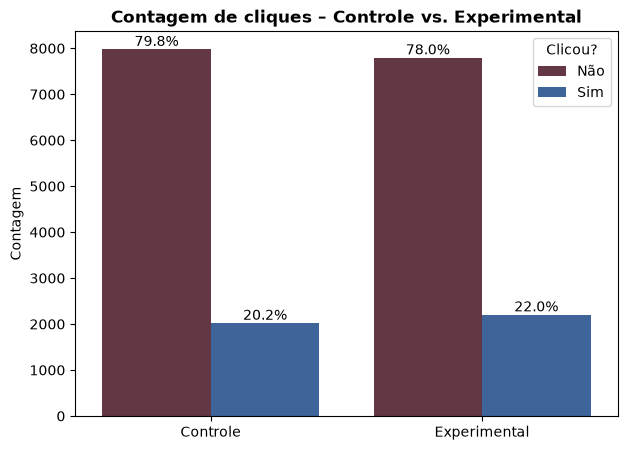

In [7]:
ordem = ["con", "exp"]
rotulos = {"con": "Controle", "exp": "Experimental"}

fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=df, x="group", hue="click", order=ordem,
              palette={0: "#6C2F41", 1: "#3062A8"}, ax=ax)

ax.set_xticks(range(len(ordem)))
ax.set_xticklabels([rotulos[g] for g in ordem])
ax.set_title("Contagem de cliques – Controle vs. Experimental", weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Contagem")
ax.legend(title="Clicou?", labels=["Não", "Sim"])

totais = df["group"].value_counts()
# ax.containers[0] = barras de click=0 (uma por grupo); ax.containers[1] = click=1
for container in ax.containers:
    for barra, grupo in zip(container, ordem):
        pct = barra.get_height() / totais[grupo] * 100
        ax.annotate(f"{pct:.1f}%", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                    ha="center", va="bottom", fontsize=10)
plt.show()

Ao analisar os resultados, observa-se que o grupo experimental apresentou um desempenho superior ao grupo de controle, alcançando uma **taxa de cliques de 22%**, contra 20,2% da versão original. Essa diferença **representa um aumento de 1,8 ponto percentual na CTR**, equivalente a uma melhoria relativa de aproximadamente 8,9%.

Além disso, houve uma redução na proporção de usuários que não interagiram com o botão, passando de 79,8% no grupo de controle para 78% no grupo experimental. Esses resultados sugerem que a nova chamada para ação **"Inscreva-se Agora"** pode ser mais eficiente em estimular o interesse dos visitantes e incentivar a interação com a página.

Entretanto, embora os resultados iniciais favoreçam a versão experimental, ainda é necessário avaliar a significância estatística da diferença observada, por meio de um teste de hipótese, para verificar se essa melhoria representa um efeito real da alteração ou se pode ser explicada pela variabilidade amostral. Também é importante considerar que o aumento de cliques, isoladamente, não garante um aumento nas matrículas ou contratações dos serviços oferecidos pela empresa.

## 1.5 Parâmetros

Agora irei analisar os parâmetros Alpha, Poder e Delta, eles são essenciais no estudo estatístico de um Teste A/B para definir o tamanho da amostra necessária e garantir que os resultados sejam confiáveis.

In [8]:
alpha = 0.05
power = 0.80
delta = 0.02   # absoluto: 0,02 = 2 pontos percentuais

print(f"α = {alpha} | poder = {power} | δ = {delta} ({delta*100:.0f} p.p.)")

α = 0.05 | poder = 0.8 | δ = 0.02 (2 p.p.)


<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">2 Planejamento - Tamanho de Amostra</h1>
</div>

Definir o tamanho da amostra é de extrema importância em um Teste A/B, ela é o resultado matemático dos três parâmetros, Alpha, Poder e Delta, Eles funcionam como uma balança de precisão:

- **Para reduzir o Alpha (falsos-positivos):** Se você quer ter muita certeza de que o vencedor não foi obra do acaso, você precisa de um filtro mais rigoroso. Filtros rigorosos exigem **mais dados (amostra maior)**.
- **Para aumentar o Poder (evitar falsos-negativos):** Se você quer que o teste seja altamente sensível para não deixar passar nenhuma oportunidade, você precisa coletar **mais dados (amostra maior)**.
- **Para detectar um Delta menor (Mínimo Efeito Detectável):** Pense no Delta como o tamanho de um objeto que você está procurando no fundo do mar. Se o objeto é gigante (um Delta grande, ex: aumentar conversão em 50%), você precisa de pouca luz (pouca amostra) para ver. Se o objeto é minúsculo (um Delta pequeno, ex: aumento sutil de 1%), você precisa de um holofote gigante. Esse holofote é uma **amostra massiva**. 

Vamos responder a seguinte pergunta:
> **Quantos usuários **por grupo** precisamos para detectar uma diferença de δ = 2 p.p. com α = 0,05 e poder de 80%?**

Fórmula para duas proporções (teste bilateral):

$$n = \frac{(z_{1-\alpha/2} + z_{1-\beta})^2 \,[\,p_1(1-p_1) + p_2(1-p_2)\,]}{\delta^2}, \quad p_2 = p_1 + \delta$$

O `p₁` (CTR base) normalmente vem de dados históricos. Aqui usamos o CTR observado no controle como aproximação.

In [9]:
p1 = resumo.loc["con", "CTR"]
p2 = p1 + delta

z_alpha = norm.ppf(1 - alpha / 2)
z_beta = norm.ppf(power)

num_necessario = ((z_alpha + z_beta) ** 2 * (p1 * (1 - p1) + p2 * (1 - p2))) / delta ** 2
num_necessario = int(np.ceil(num_necessario))

print(f"CTR base (controle): {p1:.4f}  →  CTR alvo: {p2:.4f}")
print(f"Usuários necessários por grupo: {num_necessario}")
print(f"Usuários que temos por grupo:   {contagem['con']} (con) / {contagem['exp']} (exp)")

if contagem.min() >= num_necessario:
    print("✅ A amostra é suficiente para detectar δ com o poder desejado.")
else:
    print("⚠️ Amostra menor que o necessário: o teste pode não detectar um efeito de tamanho δ.")

CTR base (controle): 0.2021  →  CTR alvo: 0.2221
Usuários necessários por grupo: 6555
Usuários que temos por grupo:   10000 (con) / 10000 (exp)
✅ A amostra é suficiente para detectar δ com o poder desejado.


Agora que definimos as hipóteses e os parâmetros, validamos os dados (sem SRM) e conferimos que a amostra é suficiente.
Podemos **testar** a diferença entre os botões:
1. Teste Z de duas proporções (variância **combinada**) → Z e p-valor
2. Intervalo de confiança (erro padrão **não combinado**)
3. Significância prática: comparar o IC com δ



<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">3 Teste Z de Duas Proporções</h1>
</div>

## 3.1 Estatísticas por Grupo

O Teste Z de Duas Proporções é um método estatístico utilizado para **verificar se existe uma diferença estatisticamente significativa entre as proporções de dois grupos independentes.** No contexto de um Teste A/B, ele é especialmente útil para avaliar se uma alteração realizada em uma página, botão, formulário ou anúncio provocou uma mudança em uma determinada taxa, como:
- Taxa de cliques (CTR);
- Taxa de conversão;
- Taxa de inscrições;
- Taxa de abertura de e-mails;
- Taxa de conclusão de cadastros.

Convenção de sinal do projeto: **diferença = experimental − controle**.
Assim, valores positivos significam que o botão novo ganhou.

In [10]:
resumo = df.groupby("group")["click"].agg(["count", "sum"])

n_con, x_con = resumo.loc["con", "count"], resumo.loc["con", "sum"]
n_exp, x_exp = resumo.loc["exp", "count"], resumo.loc["exp", "sum"]

ctr_con = x_con / n_con
ctr_exp = x_exp / n_exp

diff = ctr_exp - ctr_con                 # diferença absoluta (exp − con)
lift = diff / ctr_con                    # ganho relativo

print(f"Controle:      {x_con} cliques / {n_con} usuários  → CTR = {ctr_con:.4f}")
print(f"Experimental:  {x_exp} cliques / {n_exp} usuários  → CTR = {ctr_exp:.4f}")
print(f"\nDiferença absoluta (exp − con): {diff:.4f}  ({diff*100:.2f} p.p.)")
print(f"Lift relativo:                  {lift:.2%}")

Controle:      2021 cliques / 10000 usuários  → CTR = 0.2021
Experimental:  2204 cliques / 10000 usuários  → CTR = 0.2204

Diferença absoluta (exp − con): 0.0183  (1.83 p.p.)
Lift relativo:                  9.05%


O **grupo experimental registrou 2.204 cliques entre 10.000 usuários**, enquanto o **grupo de controle apresentou 2.021 cliques para a mesma quantidade de usuários**. Com isso, a nova versão do botão alcançou uma CTR de 22,04%, superando os 20,21% da versão original.

Essa diferença representa um **aumento absoluto de 1,83 ponto percentual** e uma **melhoria relativa de aproximadamente 9,05% na taxa de cliques**. Portanto, os resultados iniciais indicam que a alteração do texto do CTA pode ter contribuído positivamente para o engajamento dos visitantes com a página.

Entretanto, ainda precisamos verificar se essa diferença possui significância estatística, por meio de um teste de hipótese, para avaliar se há evidências suficientes de que a melhoria observada não ocorreu simplesmente ao acaso.

## 3.2 Checagem dos pressupostos

A aproximação normal exige pelo menos 10 cliques **e** 10 não-cliques em cada grupo.

In [11]:
for nome, n, x in [("Controle", n_con, x_con), ("Experimental", n_exp, x_exp)]:
    ok = (x >= 10) and (n - x >= 10)
    print(f"{nome:13s} cliques = {x:5d} | não cliques = {n - x:5d} → {'✅ ok' if ok else '⚠️ amostra pequena'}")

Controle      cliques =  2021 | não cliques =  7979 → ✅ ok
Experimental  cliques =  2204 | não cliques =  7796 → ✅ ok


Aqui temos uma verificação preliminar da quantidade de observações em cada categoria (cliques e não cliques), garantindo que ambos os grupos atendam ao critério mínimo de 10 observações por categoria. Como os dois grupos apresentam quantidades muito superiores a esse limite, essa condição para utilização da aproximação normal no teste de duas proporções está satisfeita.

## 3.3 Estatística Z e P-Valor

Sob H₀ os dois grupos têm o **mesmo** p, então a melhor estimativa dele junta os dois grupos (proporção **combinada**):

$$\hat{p}_{comb} = \frac{X_{con} + X_{exp}}{n_{con} + n_{exp}}; \qquad EP_{comb} = \sqrt{\hat{p}_{comb}(1-\hat{p}_{comb})\left(\tfrac{1}{n_{con}} + \tfrac{1}{n_{exp}}\right)}; \qquad Z = \frac{\hat{p}_{exp} - \hat{p}_{con}}{EP_{comb}}$$

In [12]:
# Cálculo da proporção combinada (p_comb)
p_comb = (x_con + x_exp) / (n_con + n_exp)

# Cálculo do erro padrão combinado (EP_comb)
ep_comb = np.sqrt(p_comb * (1 - p_comb) * (1 / n_con + 1 / n_exp))

# Cálculo estatística Z (Z_stat)
z_stat = diff / ep_comb

# Cálculo do valor crítico (Z_critico)
z_critico = norm.ppf(1 - alpha / 2)  

# Cálculo do P-valor
p_valor = 2 * norm.sf(abs(z_stat))

print("---"*30)
print(f"Proporção combinada:     {p_comb:.5f}")
print(f"Erro padrão combinado:   {ep_comb:.5f}")
print(f"Estatística Z:           {z_stat:.2f}")
print(f"Valor crítico (±):       {z_critico:.2f}")
print(f"P-valor:                 {p_valor:.5f}")
print("---"*30)

print("--- Resultado Estatístico ---")
if p_valor <= alpha:
    print(f"✅ Rejeitamos H0 (p ≤ α = {alpha}): a diferença é estatisticamente significativa.")
else:
    print(f"❌ Não rejeitamos H0 (p > α = {alpha}): sem evidência suficiente de diferença.")

------------------------------------------------------------------------------------------
Proporção combinada:     0.21125
Erro padrão combinado:   0.00577
Estatística Z:           3.17
Valor crítico (±):       1.96
P-valor:                 0.00152
------------------------------------------------------------------------------------------
--- Resultado Estatístico ---
✅ Rejeitamos H0 (p ≤ α = 0.05): a diferença é estatisticamente significativa.


Após a realização do Teste Z para duas proporções, utilizando um nível de significância de 5%, **foi obtida uma estatística Z de 3,17, superior ao valor crítico de 1,96**. Além disso, o p-valor foi de aproximadamente 0,0015, ficando abaixo do nível de significância estabelecido.

Diante desses resultados, **rejeitamos a hipótese nula (H₀)**, indicando que existem evidências estatísticas de uma diferença entre as taxas de cliques dos grupos de controle e experimental.

Considerando que o grupo experimental apresentou uma CTR de 22,04%, enquanto o grupo de controle registrou 20,21%, os resultados favorecem a nova versão do botão de CTA ("Inscreva-se Agora"). Essa alteração proporcionou um aumento de 1,83 ponto percentual na taxa de cliques, equivalente a uma melhoria relativa de aproximadamente 9,05%.

Portanto, os resultados sugerem que a **nova chamada para ação apresenta um desempenho superior ao da versão original em relação à métrica analisada**, sendo uma alternativa promissora para melhorar o engajamento dos visitantes na página inicial.

## 3.4 Visualização

A curva é a distribuição de Z **assumindo H₀**. As áreas vermelhas são as regiões de rejeição (2,5% em cada cauda). Se a linha verde cair nelas, rejeitamos H₀.

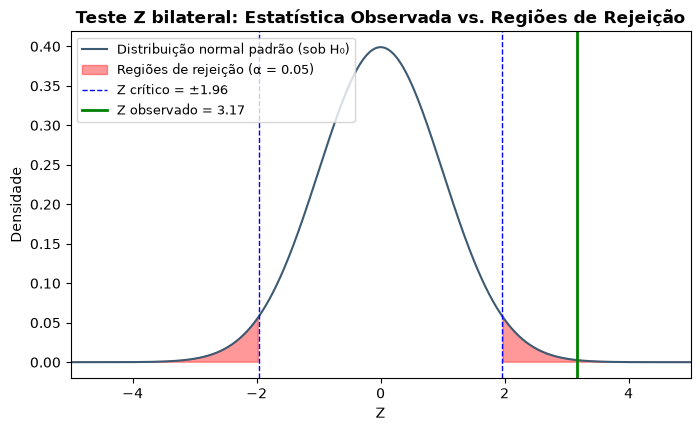

In [13]:
x = np.linspace(-5, 5, 500)
y = norm.pdf(x)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, y, color="#3D5A73", label="Distribuição normal padrão (sob H₀)")

ax.fill_between(x, y, where=(x > z_critico) | (x < -z_critico),
                color="red", alpha=0.4, label=f"Regiões de rejeição (α = {alpha})")

ax.axvline(z_critico, color="blue", ls="--", lw=1, label=f"Z crítico = ±{z_critico:.2f}")
ax.axvline(-z_critico, color="blue", ls="--", lw=1)
ax.axvline(z_stat, color="green", ls="-", lw=2, label=f"Z observado = {z_stat:.2f}")

ax.set_xlim(-5, 5)
ax.set_title("Teste Z bilateral: Estatística Observada vs. Regiões de Rejeição", weight="bold")
ax.set_xlabel("Z")
ax.set_ylabel("Densidade")
ax.legend(loc="upper left", fontsize=9)

plt.show()

No gráfico, a curva representa a distribuição normal padrão, considerando que a hipótese nula (H₀) seja verdadeira, ou seja, que a alteração do botão não tenha provocado uma diferença real na taxa de conversão.

As **regiões em vermelho representam as áreas de rejeição da hipótese nula**, delimitadas pelos valores críticos de -1,96 e +1,96, considerando um nível de significância de 5%. Isso significa que, caso a estatística Z observada ultrapasse esses limites, teremos evidências estatísticas suficientes para rejeitar H₀.

No experimento, **a estatística Z calculada foi de 3,17, representada pela linha verde**. Como esse resultado ultrapassou o limite crítico de +1,96 e se encontra dentro da região de rejeição, **podemos concluir que existe uma diferença estatisticamente significativa entre as taxas de conversão das duas versões**.

Além disso, como a estatística Z apresentou um valor positivo, considerando que a diferença foi calculada pela proporção da versão **("Inscreva-se Agora")** menos a proporção da versão **("Obtenha um Teste Gratuito")**, isso indica que a versão alterada apresentou uma taxa de conversão superior.

Portanto, os resultados fornecem evidências estatísticas de que a alteração realizada no botão influenciou positivamente o comportamento dos visitantes, aumentando a taxa de pessoas que de alguma forma interagiram com o novo botão. Do ponto de vista do negócio, isso indica que a nova versão do botão apresenta potencial para melhorar o desempenho da página e pode ser considerada para implementação.

Entretanto, antes de tomar a decisão definitiva, é importante considerar a magnitude da melhoria, sua relevância financeira e a qualidade da execução do experimento, garantindo que a diferença observada possa ser atribuída à alteração realizada.


<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">4 Intervalo de Confiança</h1>
</div>

Aqui **não** assumimos H₀, então usamos o erro padrão **não combinado** (cada grupo com seu próprio CTR):

$$IC_{95\%} = (\hat{p}_{exp} - \hat{p}_{con}) \pm z_{1-\alpha/2} \times \sqrt{\frac{\hat{p}_{exp}(1-\hat{p}_{exp})}{n_{exp}} + \frac{\hat{p}_{con}(1-\hat{p}_{con})}{n_{con}}}$$

In [14]:
ep_nao_comb = np.sqrt(ctr_exp * (1 - ctr_exp) / n_exp + ctr_con * (1 - ctr_con) / n_con)

ic_inf = diff - z_critico * ep_nao_comb
ic_sup = diff + z_critico * ep_nao_comb

print(f"Erro padrão não combinado: {ep_nao_comb:.5f}")
print(f"Diferença observada: {diff:.4f} ({diff*100:.2f} p.p.)")
print(f"IC {100*(1-alpha):.0f}%: [{ic_inf:.4f}; {ic_sup:.4f}]  →  [{ic_inf*100:.2f} p.p.; {ic_sup*100:.2f} p.p.]")

Erro padrão não combinado: 0.00577
Diferença observada: 0.0183 (1.83 p.p.)
IC 95%: [0.0070; 0.0296]  →  [0.70 p.p.; 2.96 p.p.]


A análise do intervalo de confiança de 95% apresentou limites entre 0,70 e 2,96 pontos percentuais para a diferença entre as taxas de cliques dos grupos experimental e de controle. 

Observa-se que todo o intervalo está acima de zero, indicando que os valores estimados para a **diferença entre as proporções são positivos**. Isso significa que, mesmo considerando a incerteza da estimativa, os resultados apontam para um **desempenho superior da versão experimental em relação à versão original**.

Dessa forma, temos evidências de que a alteração no texto do botão de chamada para ação ("Inscreva-se agora") contribuiu positivamente para a taxa de cliques, com uma vantagem estimada entre 0,70 e 2,96 pontos percentuais, considerando um nível de confiança de 95%.

Esse resultado reforça a conclusão obtida no teste de hipótese, segundo a qual a diferença observada entre os grupos é estatisticamente significativa e favorece a nova versão do botão.

<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">5 Significância Prática</h1>
</div>

Estatisticamente significativo não quer dizer que **vale a pena**. Comparamos o IC com δ (2 p.p., absoluto):

| Onde está o IC | Conclusão |
|---|---|
| Contém 0 | Não significativo |
| Todo abaixo de 0 | Piora significativa |
| Acima de 0, mas todo abaixo de δ | Significativo, **mas irrelevante** na prática |
| Acima de 0, atravessa δ | Há efeito, mas **incerto** se atinge δ |
| Todo acima de δ (limite inferior ≥ δ) | Significativo **e** relevante |

In [15]:
def significancia_pratica(ic_inf, ic_sup, delta):
    """Classifica o resultado combinando o IC da diferença (exp − con) com o δ."""
    if ic_inf <= 0 <= ic_sup:
        return "Não significativo: o IC contém 0 (sem evidência de efeito)."
    if ic_sup < 0:
        return "Piora significativa: o botão novo parece PIOR que o atual."
    if ic_sup < delta:
        return "Significativo, mas IRRELEVANTE na prática: todo o IC está abaixo de δ."
    if ic_inf >= delta:
        return "Significativo e RELEVANTE: mesmo o pior cenário plausível atinge δ."
    return "Efeito positivo comprovado, mas INCERTO se atinge δ: o IC atravessa δ."

conclusao_pratica = significancia_pratica(ic_inf, ic_sup, delta)
print(conclusao_pratica)

Efeito positivo comprovado, mas INCERTO se atinge δ: o IC atravessa δ.


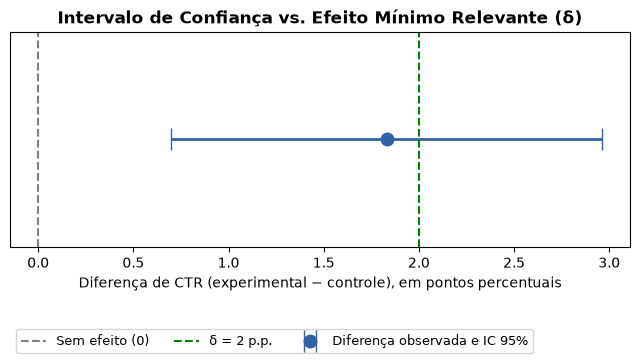

In [16]:
fig, ax = plt.subplots(figsize=(8, 2.8))

ax.errorbar(diff * 100, 0, xerr=[[ (diff - ic_inf) * 100 ], [ (ic_sup - diff) * 100 ]],
            fmt="o", color="#3062A8", capsize=8, lw=2, ms=9, label=f"Diferença observada e IC {100*(1-alpha):.0f}%")

ax.axvline(0, color="gray", ls="--", label="Sem efeito (0)")
ax.axvline(delta * 100, color="green", ls="--", label=f"δ = {delta*100:.0f} p.p.")

ax.set_yticks([])
ax.set_xlabel("Diferença de CTR (experimental − controle), em pontos percentuais")
ax.set_title("Intervalo de Confiança vs. Efeito Mínimo Relevante (δ)", weight="bold")
ax.legend(loc="upper left", fontsize=9, bbox_to_anchor=(0, -0.35), ncol=3)
plt.show()

Ao analisar o intervalo de confiança em relação ao efeito mínimo relevante (δ), estabelecido em 2 pontos percentuais, observa-se que a diferença estimada entre os grupos foi de 1,83 ponto percentual, ficando ligeiramente abaixo do ganho mínimo desejado pela empresa.

Além disso, o intervalo de confiança de 95%, compreendido entre 0,70 e 2,96 pontos percentuais, atravessa o limite de 2 pontos percentuais. Isso indica que, embora existam evidências estatísticas de que a nova versão apresenta uma taxa de cliques superior à versão original, ainda não é possível afirmar com segurança que essa melhoria alcança o nível de relevância prática estabelecido.

Dessa forma, os resultados demonstram uma melhoria estatisticamente significativa, mas a relevância prática da alteração permanece incerta. Portanto, antes de implementar definitivamente a nova versão, seria interessante avaliar se o ganho observado justifica os custos de implementação e se o aumento de cliques também proporciona benefícios em métricas mais importantes para o negócio, como cadastros, matrículas e contratação dos serviços oferecidos.

<div style="
    background-color: #3D5A73;
    color: white;
    width: 700px;
    height: 120px;                 /* define altura fixa */
    margin: 20px auto;
    border-radius: 15px;
    display: flex;                 /* ativa flexbox */
    align-items: center;           /* centraliza vertical */
    justify-content: center;       /* centraliza horizontal */
">
    <h1 style="margin: 0;">6 Conclusão</h1>
</div>

In [ ]:
# Formatação do p-valor
p_txt = ("< 0,001" if p_valor < 0.001 else f"= {p_valor:.4f}".replace(".", ","))

# Decisão estatística
resultado_estatistico = ("SIM" if p_valor <= alpha else "NÃO")

# Relatório final
relatorio = f"""
╔══════════════════════════════════════════════════════════╗
║                  RESULTADO DO TESTE A/B                 ║
╚══════════════════════════════════════════════════════════╝

  01. DESEMPENHO DOS GRUPOS
  ──────────────────────────────────────────────────────────

  {'Indicador':<25} {'CONTROLE':>12} {'EXPERIMENTAL':>16}
  {'Usuários':<25} {n_con:>12,} {n_exp:>16,}
  {'Cliques':<25} {x_con:>12,} {x_exp:>16,}
  {'CTR':<25} {ctr_con * 100:>11.2f}% {ctr_exp * 100:>15.2f}%


  02. COMPARAÇÃO DOS RESULTADOS
  ──────────────────────────────────────────────────────────

  Diferença absoluta         {(f"{diff * 100:+.2f}").replace(".", ",")} p.p.
  Lift relativo              {(f"{lift * 100:+.2f}").replace(".", ",")}%
  Intervalo de confiança     [{ic_inf * 100:.2f}; {ic_sup * 100:.2f}] p.p.


  03. TESTE DE HIPÓTESE
  ──────────────────────────────────────────────────────────

  Estatística Z              {z_stat:.2f}
  P-valor                    {p_txt}
  Nível de significância     {alpha * 100:.0f}%


  04. CONCLUSÕES
  ──────────────────────────────────────────────────────────

  Significância estatística: {resultado_estatistico}
  Significância prática:     {conclusao_pratica}

╔══════════════════════════════════════════════════════════╗
║                    FIM DO RELATÓRIO                     ║
╚══════════════════════════════════════════════════════════╝
"""

# Ajuste dos separadores decimais no relatório
relatorio = relatorio.replace(".", ",") 

print(relatorio)



╔══════════════════════════════════════════════════════════╗
║                  RESULTADO DO TESTE A/B                 ║
╚══════════════════════════════════════════════════════════╝

  01, DESEMPENHO DOS GRUPOS
  ──────────────────────────────────────────────────────────

  Indicador                     CONTROLE     EXPERIMENTAL
  Usuários                        10,000           10,000
  Cliques                          2,021            2,204
  CTR                             20,21%           22,04%


  02, COMPARAÇÃO DOS RESULTADOS
  ──────────────────────────────────────────────────────────

  Diferença absoluta         +1,83 p,p,
  Lift relativo              +9,05%
  Intervalo de confiança     [0,70; 2,96] p,p,


  03, TESTE DE HIPÓTESE
  ──────────────────────────────────────────────────────────

  Estatística Z              3,17
  P-valor                    = 0,0015
  Nível de significância     5%


  04, CONCLUSÕES
  ──────────────────────────────────────────────────────────

  

A partir da realização do Teste A/B, foi possível avaliar o desempenho de duas versões do botão de chamada para ação (CTA) presente na página inicial da empresa, buscando identificar qual delas proporcionaria uma maior taxa de cliques (CTR).

Os resultados da análise descritiva demonstraram que o grupo experimental, exposto à **nova versão do botão ("Inscreva-se agora"), apresentou uma CTR de 22,04%**, enquanto o grupo de controle, exposto à **versão original ("Garantir teste gratuito"), registrou uma taxa de 20,21%**. Essa diferença representa um aumento de 1,83 ponto percentual na taxa de cliques, equivalente a uma **melhoria relativa de aproximadamente 9,05%** em favor da versão experimental.

Para verificar se essa diferença poderia ser atribuída simplesmente à variabilidade natural das amostras, foi realizado um teste de hipótese utilizando o Teste Z para duas proporções, considerando um nível de significância de 5%. A análise apresentou uma **estatística Z de 3,17** e um **p-valor aproximado de 0,0015**, inferior ao nível de significância estabelecido. Dessa forma, **rejeitou-se a hipótese nula**, encontrando evidências estatísticas de que as taxas de cliques dos dois grupos são diferentes.

Essa conclusão também foi reforçada pelo intervalo de confiança de 95%, que apresentou limites entre 0,70 e 2,96 pontos percentuais. Como todo o intervalo está acima de zero, os resultados indicam que a nova versão do botão apresenta um desempenho superior ao da versão original em relação à métrica analisada.

Entretanto, ao avaliar a significância prática, considerando um efeito mínimo relevante de 2 pontos percentuais, observou-se que a diferença estimada de 1,83 ponto percentual ficou ligeiramente abaixo do objetivo estabelecido. Além disso, o intervalo de confiança abrange valores inferiores e superiores a esse limite, não permitindo afirmar com segurança que o ganho real alcança a relevância prática desejada pela empresa.

Portanto, conclui-se que a alteração do botão de CTA apresentou uma melhoria estatisticamente significativa na taxa de cliques, favorecendo a versão experimental. Apesar disso, sua relevância prática ainda permanece incerta diante do critério estabelecido. Como recomendação, seria interessante avaliar os custos de implementação e acompanhar outras métricas do negócio, especialmente a quantidade de cadastros, matrículas e contratações dos serviços oferecidos, para verificar se o aumento de cliques também se traduz em resultados efetivos para a empresa.